# YOLO Pose

In [1]:
import cv2
from ultralytics import YOLO
import random
import numpy as np
import matplotlib.pyplot as plt

In [2]:
model_path = r"E:\Exam  Cheating detection\models\yolov8m-pose.pt"
img_path = r"E:\Exam  Cheating detection\Data\Picture\DSC_0081_img001.png"
video_path = r"E:\Exam  Cheating detection\Data\Group\v5\DSC_0079(phone).MOV"
video_path2 = r"E:\Exam  Cheating detection\Data\Group\v4\DSC_0110.MOV"

In [3]:
list_point_names = ["nose", "left_eye", "right_eye", "left_ear", "right_ear", "left_shoulder",
                    "right_shoulder", "left_elbow", "right_elbow", "left_wrist", "right_wrist",
                    "left_hip", "right_hip", "left_knee", "right_knee", "left_ankle", "right_ankle"]
len(list_point_names)

17

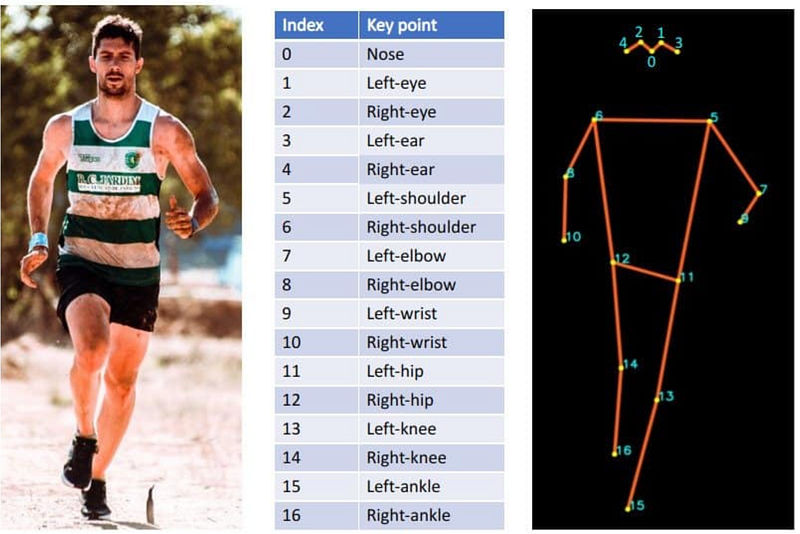

In [ ]:
point_pairs = [
    (5, 11), (6, 12), # Bədən
    (11, 12), # Ayaqlar arasında
    (0, 1), (0, 2), (1, 3), (2, 4),  # Baş
    (5, 6),  # Çiyin
    (5, 7), (7, 9),  # Sol əl
    (6, 8), (8, 10),  # Sağ əl
    (11, 13), (13, 15),  # Sol ayaq
    (12, 14), (14, 16)  # Sağ ayaq
]


0: 384x640 13 persons, 158.1ms
Speed: 12.8ms preprocess, 158.1ms inference, 28.5ms postprocess per image at shape (1, 3, 384, 640)


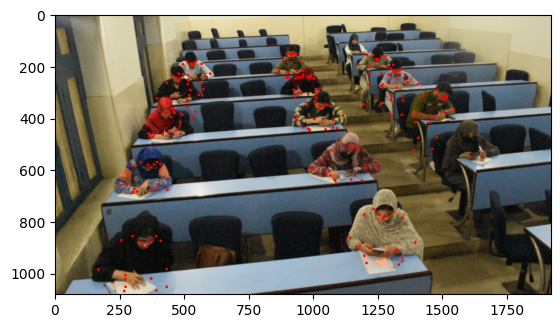

In [4]:
model = YOLO(r'E:\Exam  Cheating detection\models\yolov8m-pose.pt')
image = cv2.imread(r'E:\Exam  Cheating detection\Data\Picture\DSC_0081_img001.png')
results = model.predict(image, iou=0.4, conf=0.5)

for i in range(len(results[0].keypoints.xy)):
    keypoints = results[0].keypoints.xy[i]
    for j, point in enumerate(keypoints):
        x, y = point
        if x >= 0 and y >= 0:
            cv2.circle(image, (int(x), int(y)), 5, (0,0,255), -1)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
plt.imshow(image);

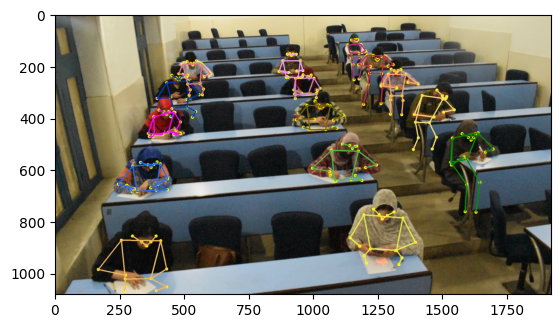

In [ ]:
import cv2
import matplotlib.pyplot as plt

model = YOLO(model_path)
image = cv2.imread(img_path)

results = model.predict(image, iou=0.4, conf=0.3, verbose=False,)


for i in range(len(results[0].keypoints.xy)):
    keypoints = results[0].keypoints.xy[i]

    random.seed(int(i+100))
    color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))

    # Nöqtələr
    for j, point in enumerate(keypoints):
        x, y = point
        if x > 0 and y > 0:  # baxırıq hər 2 kordinat 0 dan böyük olsun
            cv2.circle(image, (int(x), int(y)), 6, (0, 255, 255), -1)

    # Nöqtələri birləşdirik
    for pair in point_pairs:
        start, end = pair
        if keypoints[start][0] > 0 and keypoints[start][1] > 0 and keypoints[end][0] > 0 and keypoints[end][1] > 0:  # baxırıq hər 2 kordinat 0 dan böyük olsun
            x1, y1 = int(keypoints[start][0]), int(keypoints[start][1])
            x2, y2 = int(keypoints[end][0]), int(keypoints[end][1])
            cv2.line(image, (x1, y1), (x2, y2), color, 3)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB) 
plt.imshow(image)
plt.show()

# Video analiz

In [ ]:
def process_video_with_tracking(model, input_video_path, show_video=True, save_video=False, output_video_path="output_video.mp4"):
    cap = cv2.VideoCapture(input_video_path)

    if not cap.isOpened():
        raise Exception("Error: Could not open video file.")

    fps = int(cap.get(cv2.CAP_PROP_FPS))
    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

    if save_video:
        fourcc = cv2.VideoWriter_fourcc(*'mp4v')
        out = cv2.VideoWriter(output_video_path, fourcc, fps/2, (frame_width, frame_height))

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        results = model.track(frame, iou=0.5, conf=0.2, persist=True, imgsz=640, verbose=False, tracker="botsort.yaml")

        if results[0].boxes.id != None:
            boxes = results[0].boxes.xyxy.cpu().numpy().astype(int)
            ids = results[0].boxes.id.cpu().numpy().astype(int)

            for box, id in zip(boxes, ids):
                random.seed(int(id))
                color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))
                
                cv2.rectangle(frame, (box[0], box[1]), (box[2], box[3],), color, 2)
                cv2.putText(
                    frame,
                    f"Id {id}",
                    (box[0], box[1]),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2,
                )

            for i, id in enumerate(ids):
                keypoints = results[0].keypoints.xy[i]

                random.seed(int(id))
                color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))

                for j, point in enumerate(keypoints):
                    x, y = point
                    if x > 0 and y > 0:
                        cv2.circle(frame, (int(x), int(y)), 3, (0, 255, 255), -1)

                for pair in point_pairs:
                    start, end = pair
                    if keypoints[start][0] > 0 and keypoints[start][1] > 0 and keypoints[end][0] > 0 and keypoints[end][1] > 0: 
                        x1, y1 = int(keypoints[start][0]), int(keypoints[start][1])
                        x2, y2 = int(keypoints[end][0]), int(keypoints[end][1])
                        cv2.line(frame, (x1, y1), (x2, y2), color, 2)

        if save_video:
            out.write(frame)

        if show_video:
            frame = cv2.resize(frame, (0, 0), fx=0.6, fy=0.6) 
            cv2.imshow("frame", frame)

        if cv2.waitKey(int(1000/fps)) & 0xFF == ord("q"):
            break

    cap.release()
    if save_video:
        out.release()

    cv2.destroyAllWindows()



model = YOLO(model_path) 
process_video_with_tracking(model, video_path, show_video=True, save_video=False, output_video_path="output_video.mp4")


# Kamera üçün

In [ ]:
def process_video_with_tracking(model, cap_number):
    cap = cv2.VideoCapture(cap_number)

    if not cap.isOpened():
        raise Exception("Error: Could not open video capture.")

    cap.set(cv2.CAP_PROP_FRAME_WIDTH, 1280)
    cap.set(cv2.CAP_PROP_FRAME_HEIGHT, 720)

    while True:
        ret, frame = cap.read()
        if not ret:
            break
        results = model.track(frame, iou=0.4, conf=0.5, persist=True, imgsz=608, verbose=False, tracker="botsort.yaml")

        if results[0].boxes.id is not None:  # this will ensure that id is not None -> exist tracks
            boxes = results[0].boxes.xyxy.cpu().numpy().astype(int)
            ids = results[0].boxes.id.cpu().numpy().astype(int)

            for box, id in zip(boxes, ids):
                random.seed(int(id))
                color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))

                cv2.rectangle(frame, (box[0], box[1]), (box[2], box[3]), color, 2)
                cv2.putText(
                    frame,
                    f"Id {id}",
                    (box[0], box[1]),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.5,
                    (0, 255, 255),
                    2,
                )

            for i, id in enumerate(ids):
                keypoints = results[0].keypoints.xy[i]

                random.seed(int(id))
                color = (random.randint(0, 255), random.randint(0, 255), random.randint(0, 255))

                for j, point in enumerate(keypoints):
                    x, y = point
                    if x > 0 and y > 0:
                        cv2.circle(frame, (int(x), int(y)), 3, (0, 255, 255), -1)

                for pair in point_pairs:
                    start, end = pair
                    if keypoints[start][0] > 0 and keypoints[start][1] > 0 and keypoints[end][0] > 0 and keypoints[end][1] > 0: 
                        x1, y1 = int(keypoints[start][0]), int(keypoints[start][1])
                        x2, y2 = int(keypoints[end][0]), int(keypoints[end][1])
                        cv2.line(frame, (x1, y1), (x2, y2), color, 2)

        cv2.imshow("frame", frame)

        if cv2.waitKey(1) & 0xFF == ord("q"):
            break

    cap.release()

    cv2.destroyAllWindows()


model = YOLO(model_path)
process_video_with_tracking(model, 0)
